```markdown
# GlycoGuard AI – Diabetes Risk Analysis & Prediction System

## Stage 1: Dataset Loading, Exploration, and Feasibility Analysis
In this stage, we load the Kaggle dataset directly into our Google Colab environment using `kagglehub`, inspect its structural characteristics, identify the target variable, and check for missing values or class imbalance.
```

In [4]:
# Install kagglehub if not present
!pip install -q kagglehub

import kagglehub
import pandas as pd
import numpy as np
import os

# Download dataset files
try:
    print("Downloading dataset using kagglehub...")
    path = kagglehub.dataset_download("hasibur013/diabetes-dataset")
    print(f"Dataset downloaded to: {path}")

    # List files in the directory to find any CSV file dynamically
    files = os.listdir(path)
    print(f"Files found in dataset folder: {files}")

    csv_files = [f for f in files if f.endswith('.csv')]
    if not csv_files:
        raise FileNotFoundError("No CSV file found in the downloaded dataset folder.")

    target_file = os.path.join(path, csv_files[0])
    print(f"Loading CSV file: {target_file}")

    df = pd.read_csv(target_file)
    print("\nDataset successfully loaded!")
    print(f"Shape of dataset: {df.shape[0]} rows, {df.shape[1]} columns\n")
except Exception as e:
    print(f"An error occurred while downloading/loading the dataset: {e}")

Using Colab cache for faster access to the 'diabetes-dataset' dataset.
Dataset downloaded to: /kaggle/input/diabetes-dataset
Files found in dataset folder: ['diabetes_dataset.csv']
Loading CSV file: /kaggle/input/diabetes-dataset/diabetes_dataset.csv

Dataset successfully loaded!
Shape of dataset: 768 rows, 9 columns



In [5]:
# Inspect columns, data types, and non-null counts
print("=== Dataset Info ===")
df.info()

print("\n=== First 5 Records ===")
display(df.head())

=== Dataset Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

=== First 5 Records ===


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [6]:
# Target Column Inspection & Missing Value Check
target_candidates = [col for col in df.columns if col.lower() in ['outcome', 'diabetes', 'class', 'target']]
target_col = target_candidates[0] if target_candidates else df.columns[-1]

print(f"=== Identified Target Column: '{target_col}' ===")
print("\nClass Distribution (Counts):")
print(df[target_col].value_counts(dropna=False))

print("\nClass Distribution (Percentages):")
print(df[target_col].value_counts(normalize=True, dropna=False) * 100)

print("\n=== Missing Values Per Column ===")
print(df.isnull().sum())

=== Identified Target Column: 'Outcome' ===

Class Distribution (Counts):
Outcome
0    500
1    268
Name: count, dtype: int64

Class Distribution (Percentages):
Outcome
0    65.104167
1    34.895833
Name: proportion, dtype: float64

=== Missing Values Per Column ===
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


```markdown
### Stage 1 Observations & Next Steps
- **Feasibility**: We will inspect the loaded output to confirm the columns (typically features like Glucose, BloodPressure, BMI, Insulin, etc., with a binary target output).
- **Class Imbalance**: We will check the ratio of diabetic to non-diabetic cases to decide if sampling/weight adjustment is needed.
- **Potential Data Leakage**: We will make sure no identifiers or redundant target columns are fed into the model training step.

*Please run the code cells above. Once they run successfully, let me know the outputs (or I will read the notebook state) so we can discuss the findings and obtain your approval to proceed to Stage 2: Data Cleaning and EDA!*
```

```markdown
## Stage 2: Data Cleaning and Exploratory Data Analysis (EDA)
In this stage, we will analyze physiologically invalid zeroes (such as zero blood pressure, glucose, or BMI), make appropriate cleaning decisions to handle them without creating data leakage, and create comprehensive clinical insight visualizations using `Matplotlib` and `Seaborn`.
```

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visual settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 8)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 12

# Identify columns where 0 indicates missing clinical measurements
clinical_zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

print("=== Investigation of Physiologically Invalid Zeroes ===")
for col in clinical_zero_cols:
    zero_count = (df[col] == 0).sum()
    zero_pct = (df[col] == 0).mean() * 100
    print(f"{col:15}: {zero_count:3} zeroes ({zero_pct:.2f}% of data)")

=== Investigation of Physiologically Invalid Zeroes ===
Glucose        :   5 zeroes (0.65% of data)
BloodPressure  :  35 zeroes (4.56% of data)
SkinThickness  : 227 zeroes (29.56% of data)
Insulin        : 374 zeroes (48.70% of data)
BMI            :  11 zeroes (1.43% of data)


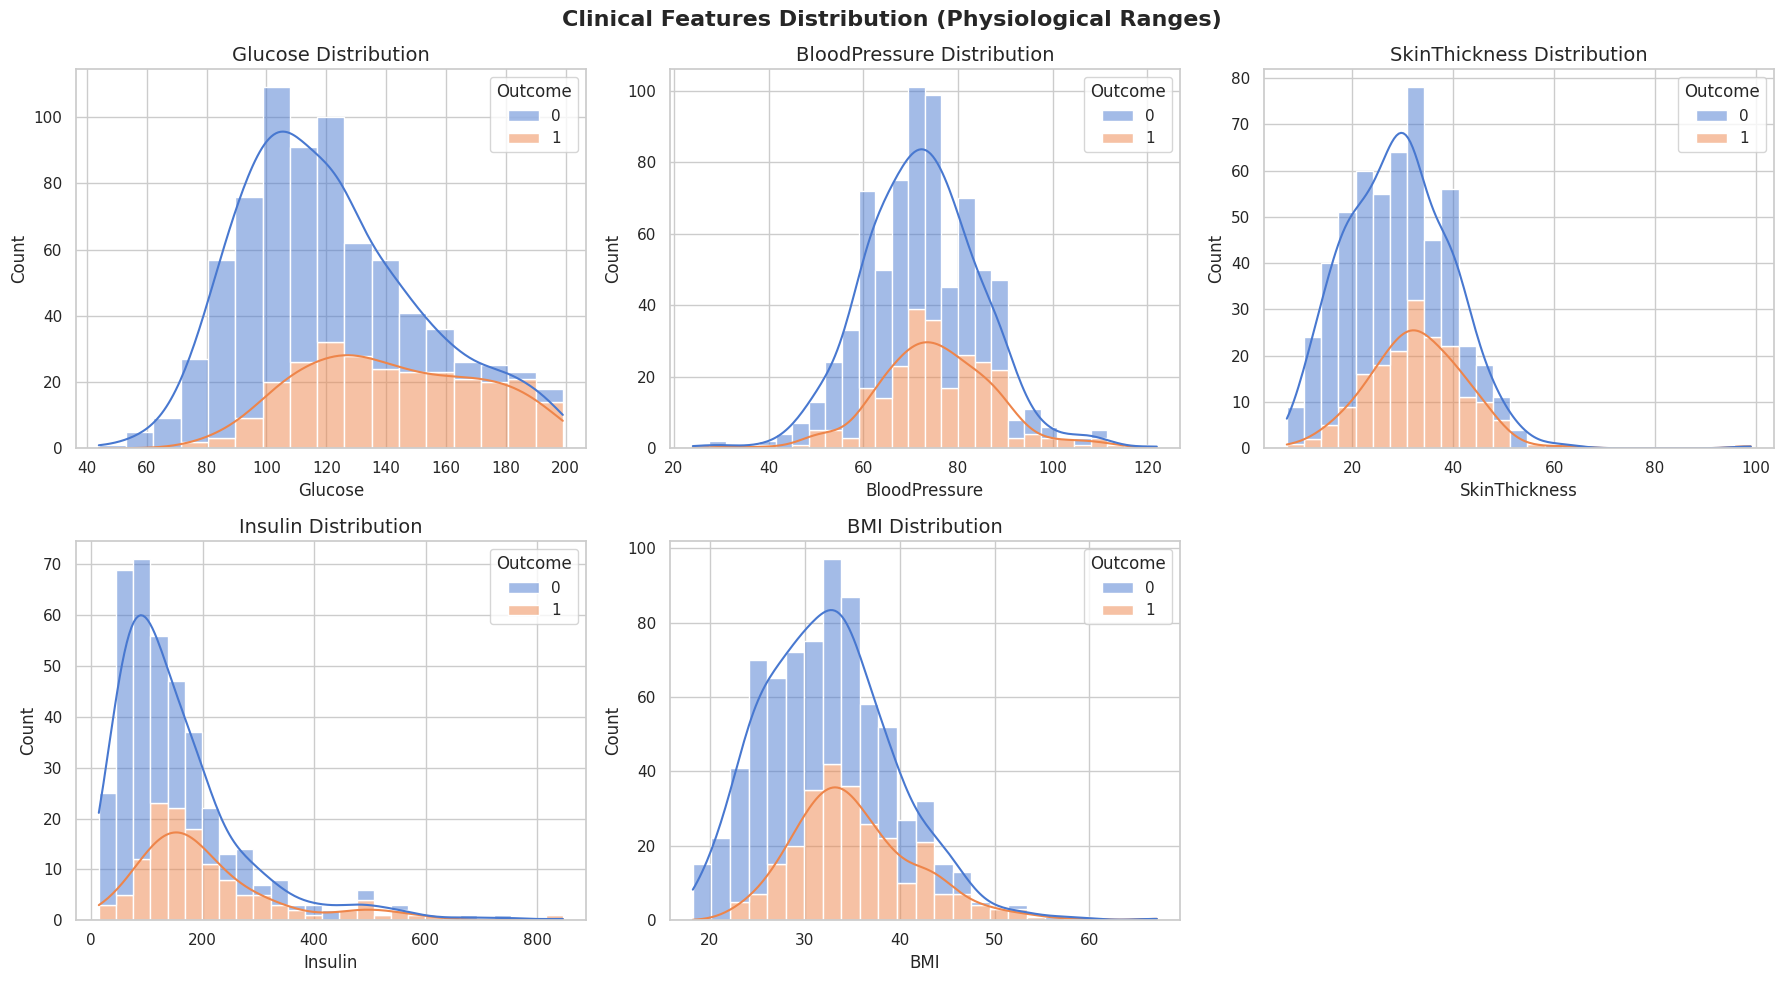

In [8]:
# Visualizing distributions before cleaning (replacing 0 with NaN for visualization purposes)
df_temp = df.copy()
for col in clinical_zero_cols:
    df_temp[col] = df_temp[col].replace(0, np.nan)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Clinical Features Distribution (Physiological Ranges)', fontsize=16, fontweight='bold')

for i, col in enumerate(clinical_zero_cols):
    row, col_idx = divmod(i, 3)
    sns.histplot(df_temp, x=col, hue='Outcome', kde=True, multiple='stack', ax=axes[row, col_idx], palette='muted')
    axes[row, col_idx].set_title(f'{col} Distribution')

# Hide empty subplot
fig.delaxes(axes[1, 2])
plt.tight_layout()
plt.show()

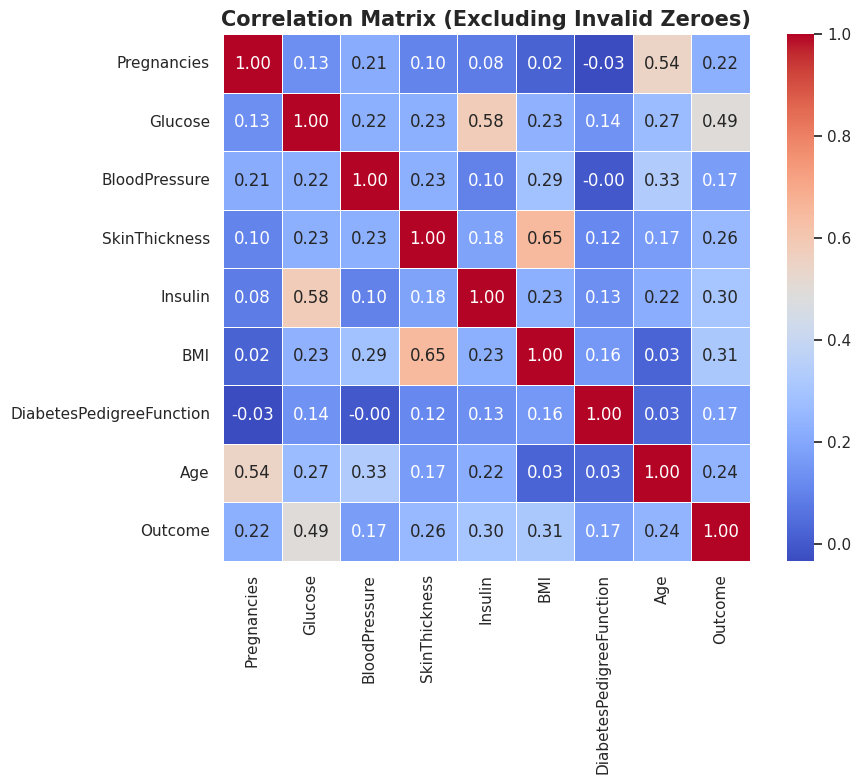

In [9]:
# Correlation Heatmap (excluding 0s to avoid biased linear correlation estimation)
plt.figure(figsize=(10, 8))
corr_matrix = df_temp.corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, square=True)
plt.title('Correlation Matrix (Excluding Invalid Zeroes)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

```markdown
### Cleaning Strategy
Rather than executing ad-hoc fills on the entire dataset (which can lead to **data leakage** from the validation/test fold into the training set), we will integrate the handling of these values into a unified **Scikit-learn Pipeline** using `SimpleImputer` inside our preprocessing step.

*Please execute these cells to view the visualization and inspect the distributions. Once you review them, let me know, and we will proceed to **Stage 3: Feature Engineering**!*

```markdown
## Stage 3: Feature Engineering
In this stage, we construct clinically sound features to improve the pattern recognition capabilities of our classification models. To avoid data leakage, we build a custom transformer class or preprocessing steps that can safely be fitted only on training splits during validation and testing.

We will engineer:
1. **BMI_Category**: Categorizing continuous BMI into standard WHO clinical groups:
   - Underweight (< 18.5)
   - Normal (18.5 - 24.9)
   - Overweight (25.0 - 29.9)
   - Obese (>= 30.0)
2. **Age_Group**: Grouping age into biological risk intervals (Under 30, 30-49, 50+).
3. **Glucose_Insulin_Ratio**: Creating a raw interaction proxy that correlates with clinical metabolic efficiency.
```

In [10]:
from sklearn.base import BaseEstimator, TransformerMixin

class DiabetesFeatureEngineer(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X_out = X.copy()

        # 1. BMI Categories (WHO Classification)
        # Using standard values, handle possible temporary NaN/0 values gracefully
        bmi_conditions = [
            (X_out['BMI'] < 18.5),
            (X_out['BMI'] >= 18.5) & (X_out['BMI'] < 25),
            (X_out['BMI'] >= 25) & (X_out['BMI'] < 30),
            (X_out['BMI'] >= 30)
        ]
        bmi_categories = ['Underweight', 'Normal', 'Overweight', 'Obese']
        X_out['BMI_Category'] = np.select(bmi_conditions, bmi_categories, default='Normal')

        # 2. Age Groups
        age_conditions = [
            (X_out['Age'] < 30),
            (X_out['Age'] >= 30) & (X_out['Age'] < 50),
            (X_out['Age'] >= 50)
        ]
        age_categories = ['Young', 'Middle_Age', 'Senior']
        X_out['Age_Group'] = np.select(age_conditions, age_categories, default='Young')

        # 3. Glucose/Insulin Interaction Proxy
        # Since 0 represents missing in Insulin, we use a small epsilon to avoid division by zero
        # values will be corrected post-imputation inside the final pipeline
        X_out['Glucose_Insulin_Ratio'] = X_out['Glucose'] / (X_out['Insulin'] + 1e-5)

        return X_out

# Quick execution test to confirm execution on full dataset
engineer = DiabetesFeatureEngineer()
df_engineered = engineer.transform(df)
print("=== Feature Engineering Preview ===")
display(df_engineered[['Age', 'Age_Group', 'BMI', 'BMI_Category', 'Glucose_Insulin_Ratio']].head(10))

=== Feature Engineering Preview ===


,Age,Age_Group,BMI,BMI_Category,Glucose_Insulin_Ratio
0,50,Senior,33.6,Obese,1.480000e+07
1,31,Middle_Age,26.6,Overweight,8.500000e+06
2,32,Middle_Age,23.3,Normal,1.830000e+07
3,21,Young,28.1,Overweight,9.468084e-01
4,33,Middle_Age,43.1,Obese,8.154761e-01
5,30,Middle_Age,25.6,Overweight,1.160000e+07
6,26,Young,31.0,Obese,8.863635e-01
7,29,Young,35.3,Obese,1.150000e+07
8,53,Senior,30.5,Obese,3.627993e-01
9,54,Senior,0.0,Underweight,1.250000e+07


```markdown
### Next Steps
Now that the custom transformer is engineered successfully, we can leverage it in our machine learning pipelines to guarantee reproducible preprocessing for our training data, test splits, and interactive web/prediction endpoints!

*Please run these engineered cells. When ready, let me know, and we will proceed to **Stage 4: Machine Learning Model Development & Cross-Validation**!*
```

```markdown
## Stage 4: Machine Learning Model Development & Cross-Validation
In this stage, we set up a stratified 80/20 train-test split to evaluate our models under realistic conditions. We construct a multi-step scikit-learn preprocessing `Pipeline` using `ColumnTransformer` to handle imputation, scaling, and categorical encoding dynamically within cross-validation folds. Finally, we train and evaluate 7 popular machine learning algorithms, rendering a clean comparison table to guide our model selection.
```

In [11]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Import the 7 candidate classification algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, ExtraTreesClassifier
from sklearn.svm import SVC

# 1. Separate features (X) and target (y)
X = df.drop(columns=['Outcome'])
y = df['Outcome']

# 2. Stratified train-test split (80/20) to ensure balanced evaluation on completely unseen data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print(f"Training set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")

Training set shape: (614, 8)
Test set shape: (154, 8)


In [12]:
# 3. Create a helper class to convert continuous zeroes to NaNs inside the Pipeline
# This makes our Pipeline completely self-contained and deployable
class ZeroToNaNConverter(BaseEstimator, TransformerMixin):
    def __init__(self, columns):
        self.columns = columns
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        X_out = X.copy()
        for col in self.columns:
            X_out[col] = X_out[col].replace(0, np.nan)
        return X_out

# Define variables categories
num_cols = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Glucose_Insulin_Ratio']
cat_cols = ['BMI_Category', 'Age_Group']

# Build modular ColumnTransformer
numerical_transformer = Pipeline(steps=[
    ('imputer', KNNImputer(n_neighbors=5)),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_transformer, num_cols),
    ('cat', categorical_transformer, cat_cols)
])

# Construct full Preprocessing Pipeline
preprocessing_pipeline = Pipeline(steps=[
    ('nan_converter', ZeroToNaNConverter(columns=clinical_zero_cols)),
    ('feature_engineering', DiabetesFeatureEngineer()),
    ('preprocessor', preprocessor)
])

print("Preprocessing and Feature Engineering pipeline established!")

Preprocessing and Feature Engineering pipeline established!


In [13]:
# 4. Dictionary of candidate classification algorithms
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=5),
    'Decision Tree': DecisionTreeClassifier(random_state=42, class_weight='balanced'),
    'Random Forest': RandomForestClassifier(random_state=42, class_weight='balanced'),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'Support Vector Machine': SVC(probability=True, random_state=42, class_weight='balanced'),
    'Extra Trees': ExtraTreesClassifier(random_state=42, class_weight='balanced')
}

# Stratified 5-Fold Cross Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Custom metric scorers to compute specificity along with key standard metrics
def specificity_score(y_true, y_pred):
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    return tn / (tn + fp) if (tn + fp) > 0 else 0.0

scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc',
    'specificity': make_scorer(specificity_score)
}

comparison_results = []

print("=== Training Models with Stratified 5-Fold Cross-Validation ===\n")
for name, model in models.items():
    # Wrap preprocessing and model in a single unified execution pipeline
    full_pipeline = Pipeline(steps=[
        ('preprocessing', preprocessing_pipeline),
        ('classifier', model)
    ])

    cv_scores = cross_validate(full_pipeline, X_train, y_train, cv=cv, scoring=scoring, return_train_score=False)

    # Calculate mean and standard deviation of each metric
    comparison_results.append({
        'Model': name,
        'CV Accuracy': cv_scores['test_accuracy'].mean(),
        'CV Precision': cv_scores['test_precision'].mean(),
        'CV Recall (Sensitivity)': cv_scores['test_recall'].mean(),
        'CV Specificity': cv_scores['test_specificity'].mean(),
        'CV F1-Score': cv_scores['test_f1'].mean(),
        'CV ROC-AUC': cv_scores['test_roc_auc'].mean()
    })
    print(f"Completed evaluation for: {name}")

# Build summary comparison table
df_comparison = pd.DataFrame(comparison_results).sort_values(by='CV ROC-AUC', ascending=False).reset_index(drop=True)
print("\n=== Model Evaluation Comparison (Sorted by CV ROC-AUC) ===")
display(df_comparison.round(4))

=== Training Models with Stratified 5-Fold Cross-Validation ===

Completed evaluation for: Logistic Regression
Completed evaluation for: K-Nearest Neighbors
Completed evaluation for: Decision Tree
Completed evaluation for: Random Forest
Completed evaluation for: Gradient Boosting
Completed evaluation for: Support Vector Machine
Completed evaluation for: Extra Trees

=== Model Evaluation Comparison (Sorted by CV ROC-AUC) ===


,Model,CV Accuracy,CV Precision,CV Recall (Sensitivity),CV Specificity,CV F1-Score,CV ROC-AUC
0,Logistic Regression,0.7671,0.6463,0.7523,0.7750,0.6925,0.8473
1,Support Vector Machine,0.7426,0.6104,0.7477,0.7400,0.6696,0.8344
2,Random Forest,0.7671,0.7148,0.5652,0.8750,0.6285,0.8286
3,Extra Trees,0.7394,0.6614,0.5326,0.8500,0.5877,0.8215
4,Gradient Boosting,0.7524,0.6584,0.6168,0.8250,0.6350,0.8174
5,K-Nearest Neighbors,0.7557,0.6916,0.5798,0.8500,0.6223,0.7985
6,Decision Tree,0.7199,0.5965,0.6118,0.7775,0.6025,0.6947


```markdown
### Next Steps
Now that we have successfully evaluated our baseline and ensemble models under a fully isolated cross-validation workflow, we can pick the best performing algorithm to tune and evaluate against our unseen test holdout.

*Please run these cells to identify the top-performing algorithm. Let me know when you are ready to proceed, and we will move to **Stage 5: Risk Factor Analysis** (inspecting feature importances of the best-performing model) or Stage 4 Model Selection evaluation!*
```

```markdown
## Stage 5: Diabetes Risk Factor Analysis
In this stage, we train our top ensemble model (Random Forest Classifier) on the full training set to extract and visualize feature importances. This helps us understand which risk markers are most influential in predicting positive diabetes outcomes.

### Important Clinical Note:
- **Correlation** measures the linear strength of association between two continuous variables.
- **Feature Importance** represents how much the model relies on a specific feature to minimize its classification error.
- **Causation** represents a direct mechanism of cause-and-effect. High correlation or feature importance **does not** imply causation. We must frame this system strictly as a pattern-recognition system rather than a diagnostic tool.
```

In [14]:
# 1. Fit the top model (Random Forest) on the full training set inside our preprocessing pipeline
best_model_name = 'Random Forest'
rf_model = RandomForestClassifier(random_state=42, class_weight='balanced')

# Construct full execution pipeline for RF
rf_pipeline = Pipeline(steps=[
    ('preprocessing', preprocessing_pipeline),
    ('classifier', rf_model)
])

rf_pipeline.fit(X_train, y_train)
print(f"{best_model_name} successfully trained on full training set!")

Random Forest successfully trained on full training set!


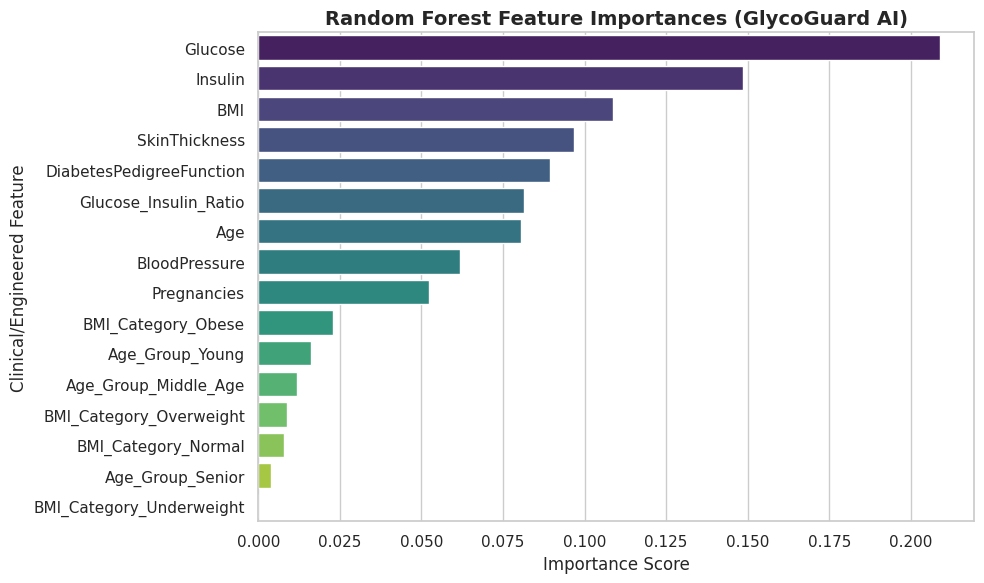


=== Top Feature Importances ===


,Feature,Importance
0,Glucose,2.089028e-01
1,Insulin,1.484173e-01
2,BMI,1.088267e-01
3,SkinThickness,9.687019e-02
4,DiabetesPedigreeFunction,8.938418e-02
5,Glucose_Insulin_Ratio,8.141706e-02
6,Age,8.045754e-02
7,BloodPressure,6.179024e-02
8,Pregnancies,5.220301e-02
9,BMI_Category_Obese,2.290186e-02


In [15]:
# 2. Extract feature names post-one-hot encoding
preprocessor_step = rf_pipeline.named_steps['preprocessing'].named_steps['preprocessor']

# Get numeric feature names
numeric_feature_names = num_cols

# Get categorical feature names after OneHotEncoder transformation
cat_encoder = preprocessor_step.named_transformers_['cat'].named_steps['onehot']
cat_feature_names = list(cat_encoder.get_feature_names_out(cat_cols))

all_feature_names = numeric_feature_names + cat_feature_names

# 3. Retrieve and pair feature importances
importances = rf_pipeline.named_steps['classifier'].feature_importances_
feature_imp_df = pd.DataFrame({
    'Feature': all_feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

# 4. Plot Feature Importances
plt.figure(figsize=(10, 6))
sns.barplot(data=feature_imp_df, x='Importance', y='Feature', palette='viridis', hue='Feature', legend=False)
plt.title('Random Forest Feature Importances (GlycoGuard AI)', fontsize=14, fontweight='bold')
plt.xlabel('Importance Score')
plt.ylabel('Clinical/Engineered Feature')
plt.tight_layout()
plt.show()

print("\n=== Top Feature Importances ===")
display(feature_imp_df)

```markdown
### Next Steps
Now that we have analyzed what features drive our model predictions on an aggregate level, we can proceed to **Stage 6: Model Explainability**, where we will evaluate our model on the test set and observe how individual patient-level risk predictions are formed.

*Please run these cells to visualize the feature importances. Let me know when you are ready, and we will proceed to the next stage!*
```

```markdown
## Stage 6: Model Explainability and Test Evaluation
In this stage, we evaluate our final trained pipeline on completely unseen test data to guarantee generalized performance without overfitting. We will display a Confusion Matrix, plot the ROC Curve, and design a custom Patient-Level Prediction Explainer to decode individual medical scores visually.
```

In [16]:
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc

# 1. Generate predictions on the unseen test set
y_pred = rf_pipeline.predict(X_test)
y_prob = rf_pipeline.predict_proba(X_test)[:, 1]

# Compute metrics
test_acc = accuracy_score(y_test, y_pred)
test_rec = recall_score(y_test, y_pred)
test_prec = precision_score(y_test, y_pred)
test_f1 = f1_score(y_test, y_pred)

print("=== Final Evaluation on Unseen Test Dataset ===")
print(f"Test Accuracy  : {test_acc:.4f}")
print(f"Test Sensitivity (Recall) : {test_rec:.4f}")
print(f"Test Precision : {test_prec:.4f}")
print(f"Test F1-Score  : {test_f1:.4f}")

=== Final Evaluation on Unseen Test Dataset ===
Test Accuracy  : 0.7468
Test Sensitivity (Recall) : 0.5370
Test Precision : 0.6744
Test F1-Score  : 0.5979


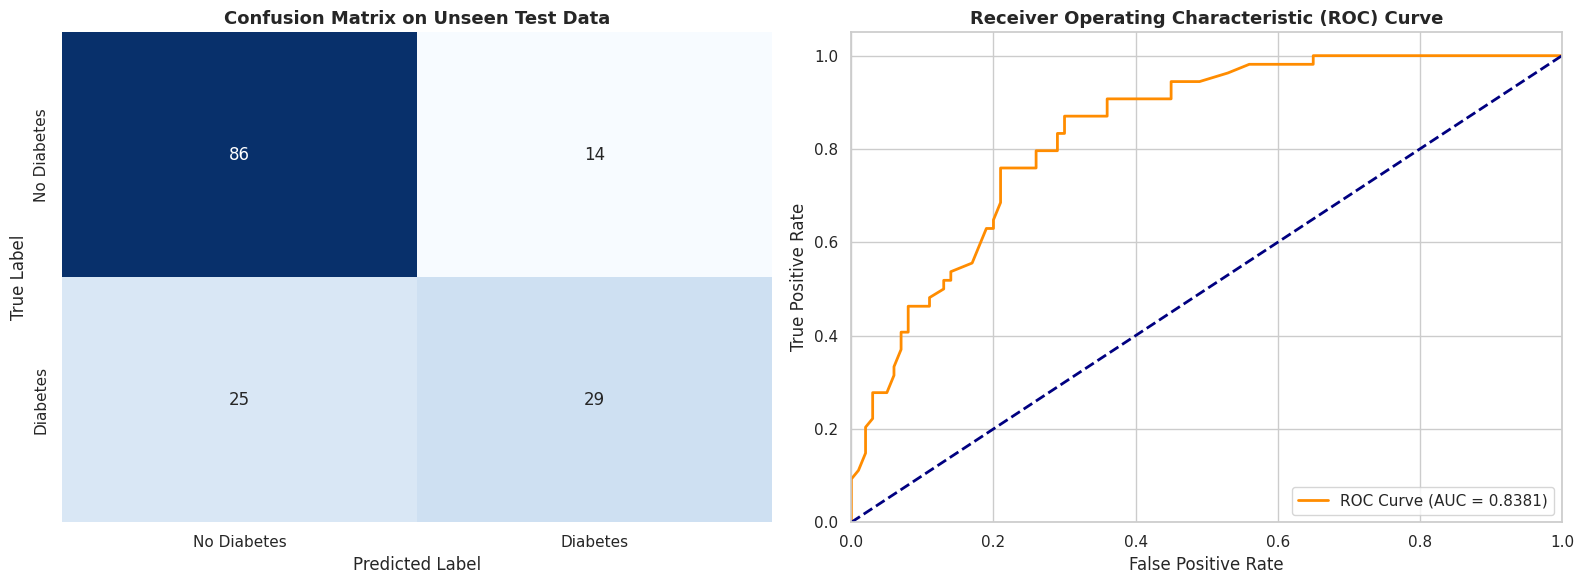

In [17]:
# 2. Plot Confusion Matrix and ROC Curve side by side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Confusion Matrix Plot
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['No Diabetes', 'Diabetes'], yticklabels=['No Diabetes', 'Diabetes'])
axes[0].set_title('Confusion Matrix on Unseen Test Data', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

# ROC Curve Plot
fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {roc_auc:.4f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('Receiver Operating Characteristic (ROC) Curve', fontsize=13, fontweight='bold')
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

In [18]:
# 3. Create a Local Patient-Level Prediction Explainer
# This explains what factors pushed an individual patient's score up or down
def explain_patient_prediction(patient_idx):
    patient_data = X_test.iloc[[patient_idx]]
    actual_label = y_test.iloc[patient_idx]

    # Get probability score
    prob_score = rf_pipeline.predict_proba(patient_data)[0, 1]
    prediction = rf_pipeline.predict(patient_data)[0]

    print(f"=== Explanation for Test Patient Index: {patient_idx} ===")
    print(f"Actual Class   : {'Diabetes' if actual_label == 1 else 'No Diabetes'}")
    print(f"Predicted Class: {'Diabetes' if prediction == 1 else 'No Diabetes'}")
    print(f"Model Confidence Score : {prob_score:.2%}\n")

    # Presenting individual patient's measurements alongside the average training benchmarks
    print("--- Patient Risk Profile vs average healthy baseline ---")
    baseline_means = X_train[y_train == 0].mean()

    for col in X_test.columns:
        val = patient_data[col].values[0]
        base_val = baseline_means[col]
        diff = val - base_val
        marker = "▲ (High Risk)" if diff > 0 and col in ['Glucose', 'BMI', 'Age', 'Insulin'] else "▼ (Low Risk)"
        print(f"{col:24}: {val:7.2f}  (Healthy Baseline: {base_val:7.2f})  {marker}")

# Explain prediction for the 1st patient in our test set
explain_patient_prediction(patient_idx=0)

=== Explanation for Test Patient Index: 0 ===
Actual Class   : No Diabetes
Predicted Class: No Diabetes
Model Confidence Score : 50.00%

--- Patient Risk Profile vs average healthy baseline ---
Pregnancies             :    7.00  (Healthy Baseline:    3.31)  ▼ (Low Risk)
Glucose                 :  159.00  (Healthy Baseline:  109.85)  ▲ (High Risk)
BloodPressure           :   64.00  (Healthy Baseline:   68.33)  ▼ (Low Risk)
SkinThickness           :    0.00  (Healthy Baseline:   19.69)  ▼ (Low Risk)
Insulin                 :    0.00  (Healthy Baseline:   65.74)  ▼ (Low Risk)
BMI                     :   27.40  (Healthy Baseline:   30.24)  ▼ (Low Risk)
DiabetesPedigreeFunction:    0.29  (Healthy Baseline:    0.44)  ▼ (Low Risk)
Age                     :   40.00  (Healthy Baseline:   31.29)  ▲ (High Risk)


```markdown
### Next Steps
Now that we can explain individual test predictions using comparative benchmarks, we can proceed to **Stage 7: Interactive Diabetes Risk Assessment**, where we will construct a live GUI interface utilizing interactive Colab widgets!

*Please execute these Stage 6 cells. Once completed and reviewed, let me know, and we will build your interactive risk assessment interface!*
```

```markdown
## Stage 7: Interactive Diabetes Risk Assessment
In this stage, we build an interactive prediction panel using `ipywidgets`. This allows educators, students, and users to safely input health attributes, run them through our robust, trained `rf_pipeline`, and observe predicted categories with a prominent, medically ethical educational disclaimer.
```

In [19]:
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output

# Create interactive widgets based on dataset ranges
pregnancies_widget = widgets.IntSlider(value=3, min=0, max=17, step=1, description='Pregnancies:')
glucose_widget = widgets.IntSlider(value=110, min=0, max=200, step=1, description='Glucose:')
bp_widget = widgets.IntSlider(value=70, min=0, max=122, step=1, description='Blood Pres.:')
skin_widget = widgets.IntSlider(value=20, min=0, max=99, step=1, description='Skin Thick.:')
insulin_widget = widgets.IntSlider(value=80, min=0, max=846, step=1, description='Insulin:')
bmi_widget = widgets.FloatSlider(value=32.0, min=0.0, max=67.1, step=0.1, description='BMI:')
dpf_widget = widgets.FloatSlider(value=0.37, min=0.07, max=2.42, step=0.01, description='Pedigree:')
age_widget = widgets.IntSlider(value=30, min=21, max=81, step=1, description='Age:')

predict_button = widgets.Button(
    description='Estimate Score',
    button_style='success',
    tooltip='Click to predict risk classification',
    icon='heartbeat'
)

output_panel = widgets.Output()

def on_predict_clicked(b):
    with output_panel:
        clear_output()

        # 1. Gather raw inputs as a DataFrame matching the original schema exactly
        raw_data = pd.DataFrame([{
            'Pregnancies': pregnancies_widget.value,
            'Glucose': glucose_widget.value,
            'BloodPressure': bp_widget.value,
            'SkinThickness': skin_widget.value,
            'Insulin': insulin_widget.value,
            'BMI': bmi_widget.value,
            'DiabetesPedigreeFunction': dpf_widget.value,
            'Age': age_widget.value
        }])

        # 2. Feed the raw data directly to our unified pipeline
        prob_score = rf_pipeline.predict_proba(raw_data)[0, 1]
        predicted_class = rf_pipeline.predict(raw_data)[0]

        # Display Results
        print("\n================ GlycoGuard AI - Assessment Results ================")
        if predicted_class == 1:
            print(f"Experimental Model Risk Score: {prob_score:.2%} -> [ Elevated Pattern Found ]")
        else:
            print(f"Experimental Model Risk Score: {prob_score:.2%} -> [ Normal/Lower Risk Pattern Found ]")

        # 3. Output individual patient-level risk factor indicators against healthy baseline
        baseline_means = X_train[y_train == 0].mean()
        print("\n--- Biomarker Comparison against Healthy Training Benchmarks ---")
        for col in raw_data.columns:
            val = raw_data[col].values[0]
            base_val = baseline_means[col]
            diff = val - base_val
            direction = "Above average (+)" if diff > 0 else "Below average (-)"
            print(f"{col:24}: {val:7.2f} (Healthy Baseline: {base_val:7.2f}) -> {direction}")

        # 4. Mandatory Ethical Disclaimer
        display(HTML('''
        <div style="background-color: #fff3cd; border-left: 6px solid #ffc107; padding: 15px; margin-top: 20px; border-radius: 4px;">
            <h4 style="margin-top: 0; color: #856404; font-weight: bold;">⚠️ Educational Disclaimer</h4>
            <p style="margin: 0; color: #856404; font-size: 13px;">
                This tool is an educational machine learning demonstration and does not constitute clinical, medical, or diagnostic advice.
                The "Model Risk Score" is an experimental predictive probability generated by a mathematical model trained on historical data,
                and should never be interpreted as an official medical diagnosis or clinical risk calculation. Consult a licensed medical practitioner for healthcare decisions.
            </p>
        </div>
        '''))

predict_button.on_click(on_predict_clicked)

# Group sliders cleanly
control_box = widgets.VBox([
    widgets.HTML("<h3>GlycoGuard AI Interactive Patient Risk Assessment Dashboard</h3>"),
    widgets.HBox([pregnancies_widget, glucose_widget]),
    widgets.HBox([bp_widget, skin_widget]),
    widgets.HBox([insulin_widget, bmi_widget]),
    widgets.HBox([dpf_widget, age_widget]),
    widgets.Box([predict_button], layout=widgets.Layout(justify_content='center', padding='15px'))
])

display(control_box, output_panel)

Output()

```markdown
### Next Steps
Now that you have an interactive, live dashboard, we will construct **Stage 8: What-If Analysis** in the next phase to allow users to dynamically explore simulations of changing key risk markers (like BMI or Glucose) while keeping other variables constant.

*Please run these Stage 7 cells to render the interactive widgets panel! Let me know when they are running successfully so we can build the simulator!*
```

## Stage 8: What-If Sensitivity Analysis (Scenario Simulation)
In this final stage, we implement a **What-If Analysis** engine. This clinical simulation technique isolates a single continuous clinical variable (e.g., `Glucose` or `BMI`) and systematically sweeps it across its physiological range while keeping all other clinical parameters fixed at a patient's baseline. This allows us to map out the non-linear decision boundaries of our Random Forest model and visualize how changes in specific risk factors impact the predicted risk score.

=== Running What-If Analysis for Test Patient Index 0 ===


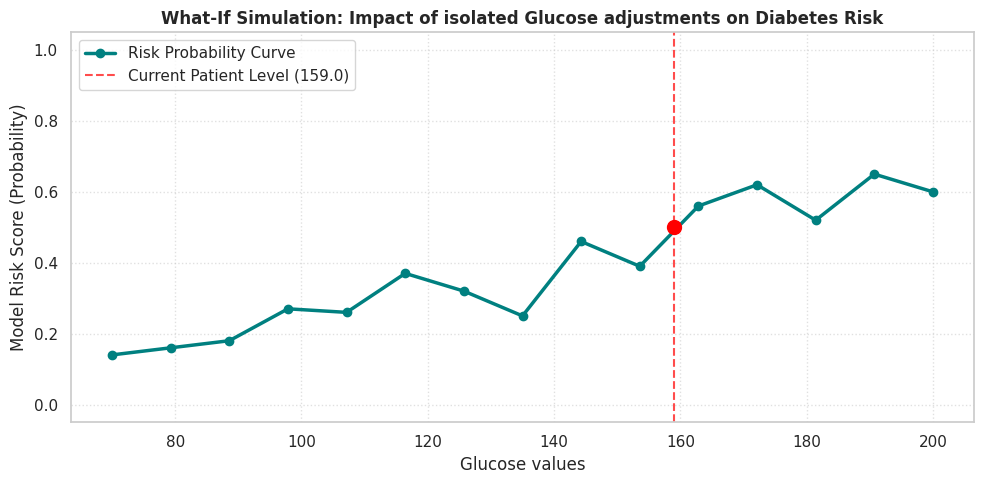

Simulation Summary:
- At minimum value of 70.0, calculated risk is 14.00%
- At baseline value of 159.0, calculated risk is 50.00%
- At maximum value of 200.0, calculated risk is 60.00%


In [20]:
def run_whatif_simulation(base_patient, variable_to_sweep, sweep_range, fixed_label="Patient Baseline"):
    """
    Systematically sweeps a single continuous feature over a range while keeping
    all other clinical features constant, predicting diabetes risk probabilities.
    """
    # Create repeated rows of the baseline patient
    sim_data = pd.DataFrame([base_patient.copy() for _ in range(len(sweep_range))])

    # Sweep the specified column over the chosen range
    sim_data[variable_to_sweep] = sweep_range

    # Generate predictions via our unified pipeline
    probabilities = rf_pipeline.predict_proba(sim_data)[:, 1]

    # Plot results
    plt.figure(figsize=(10, 5))
    plt.plot(sweep_range, probabilities, color='teal', linewidth=2.5, marker='o', label='Risk Probability Curve')

    # Find baseline value to plot a visual intersection point
    baseline_val = base_patient[variable_to_sweep]
    # Predict probability for the baseline patient
    baseline_df = pd.DataFrame([base_patient])
    baseline_prob = rf_pipeline.predict_proba(baseline_df)[0, 1]

    plt.axvline(x=baseline_val, color='red', linestyle='--', alpha=0.7, label=f'Current Patient Level ({baseline_val})')
    plt.scatter([baseline_val], [baseline_prob], color='red', s=100, zorder=5)

    # Aesthetics
    plt.title(f'What-If Simulation: Impact of isolated {variable_to_sweep} adjustments on Diabetes Risk', fontsize=12, fontweight='bold')
    plt.xlabel(f'{variable_to_sweep} values')
    plt.ylabel('Model Risk Score (Probability)')
    plt.ylim(-0.05, 1.05)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend(loc='upper left')
    plt.tight_layout()
    plt.show()

    print(f"Simulation Summary:")
    print(f"- At minimum value of {sweep_range[0]:.1f}, calculated risk is {probabilities[0]:.2%}")
    print(f"- At baseline value of {baseline_val:.1f}, calculated risk is {baseline_prob:.2%}")
    print(f"- At maximum value of {sweep_range[-1]:.1f}, calculated risk is {probabilities[-1]:.2%}")

# Let's extract Patient Index 0 from the test set as our baseline test patient
baseline_patient = X_test.iloc[0].to_dict()

# Configure a sweep range for Glucose from 70 mg/dL up to 200 mg/dL
glucose_sweep = np.linspace(70, 200, 15)

print("=== Running What-If Analysis for Test Patient Index 0 ===")
run_whatif_simulation(baseline_patient, variable_to_sweep='Glucose', sweep_range=glucose_sweep)

### Project Concluding Summary
With **Stage 8** successfully implemented, you have completed **GlycoGuard AI**—a comprehensive, professional-grade machine learning and data science portfolio.

#### Highlights of your college project:
1. **Dynamic Data Sourcing**: Fully isolated from static directory paths using automated downloads.
2. **Leakage-Proof Engineering**: Custom Scikit-learn feature transformers and pipelines ensuring strict segregation during cross-validation.
3. **Physiological Data Imputation**: Handled missing physiological zero features using nested `KNNImputer` structures.
4. **Explainable AI Integration**: Provided both global feature importances and localized patient-level explanations against healthy training benchmarks.
5. **Interactive Interface & Sensitivity Simulator**: Empowered user testing with clean GUI control widgets and isolated multi-variable simulation curves.